In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42

C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Rohan\miniconda3\envs\qae\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please update the gencode to avoid

In [2]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np

def angle_encoding(x):
    num_qubits = len(x)
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[i], i)
    return circuit

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def efficient_su2_encoding(x):
    num_qubits = int(np.ceil(len(x) / 4))  # EfficientSU2 expects 4 params per qubit per rep
    su2 = EfficientSU2(num_qubits=num_qubits, reps=3)

    # Pad x to match the number of parameters in EfficientSU2
    total_params = su2.num_parameters
    padded_x = np.pad(x, (0, total_params - len(x)), mode='constant')

    circuit = QuantumCircuit(num_qubits)
    circuit.compose(su2.assign_parameters(padded_x), inplace=True)
    return circuit

def amplitude_encoding(x):

    x = np.asarray(x, dtype=np.float64)

    # Replace NaNs and Infs with 0 BEFORE padding
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Pad first
    num_qubits = int(np.ceil(np.log2(len(x))))
    target_len = 2 ** num_qubits
    padded = np.pad(x, (0, target_len - len(x))).astype(np.float64)

    # Normalize
    norm = np.linalg.norm(padded)
    if norm == 0 or not np.isfinite(norm):
        # Default to |0⟩ state if invalid
        normalized = np.zeros_like(padded)
        normalized[0] = 1.0
    else:
        normalized = padded / norm

    # Safety check (this ensures Qiskit won't throw)
    assert np.isclose(np.sum(normalized**2), 1.0, atol=1e-10), f"Vector not normalized: {np.sum(normalized**2)}"

    # Create circuit
    circuit = QuantumCircuit(num_qubits)
    circuit.initialize(normalized, range(num_qubits))
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

def ansatz(num_qubits):
    return real_amplitudes(num_qubits, reps=1)
    # return pauli_two_design(num_qubits, reps=1)

def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit

In [5]:
from numpy import sqrt
from qiskit.qpy import load

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

# Create Circuit
# ae = auto_encoder_circuit(num_latent, num_trash)

# Generate some random values to bind to the AE parameters
# param_values = np.random.uniform(0, 2 * np.pi, len(ae.parameters))
# ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, param_values)})

model_name = "Models/QAE/First_N/8f_qae_dense_ra2_5k"
trained_params = np.load(f"{model_name}/trained_parameters.npy")
with open(f"{model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits

# ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

# # State Prep
# vec = [sqrt(0.5), 0, 0, sqrt(0.5)]  # For 2 qubits (like |00⟩ + |11⟩)
# Statevector(vec).draw('latex')  # Visualize

# # QC Init
# encoding = QuantumCircuit(total_qubits)
# encoding.initialize(vec, [0, 1])  # Targeting qubit 0 and 1

# qc_full = encoding.compose(ae)
# qc_full.draw('mpl') 


In [3]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [33]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

reduced_testing_data = testing_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)
# scaled_testing_data = reduced_testing_data

reduced_normal_training_data = normal_training_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)
# scaled_normal_training_data = reduced_normal_training_data

reduced_validation_data = validation_data
scaler = MinMaxScaler(feature_range=(0, np.pi))
scaled_validation_data = scaler.fit_transform(reduced_validation_data)
# scaled_validation_data = reduced_validation_data

first_n_scaled_normal_training_data = scaled_normal_training_data[:, :8]
first_n_scaled_validation_data = scaled_validation_data[:, :8]
first_n_scaled_testing_data = scaled_testing_data[:, :8]

first_n_normal_training_data = reduced_normal_training_data[:, :8]
first_n_validation_data = reduced_validation_data[:, :8]
first_n_testing_data = reduced_testing_data[:, :8]

In [40]:
from scipy.stats import entropy
# === Expressibility calculation ===
def compute_expressibility_dataset(encoding_fn, data, num_samples=200):
    """Computes expressibility following Sim et al. (2019) as KL divergence
       between encoded state distribution and Haar random states."""
    # Get encoded statevectors
    encoded_states = []
    for i in np.random.choice(len(data), size=num_samples, replace=False):
        qc = encoding_fn(data[i])
        sv = Statevector.from_instruction(qc)
        encoded_states.append(sv.data)

    # Compute distribution of fidelities between random pairs
    fidelities = []
    for i in range(len(encoded_states)):
        for j in range(i+1, len(encoded_states)):
            f = np.abs(np.vdot(encoded_states[i], encoded_states[j]))**2
            fidelities.append(f)

    # Compare to Haar-random fidelity distribution
    haar_samples = np.random.rand(len(fidelities))  # Uniform[0,1] approx Haar
    hist_encoded, _ = np.histogram(fidelities, bins=50, range=(0,1), density=True)
    hist_haar, _ = np.histogram(haar_samples, bins=50, range=(0,1), density=True)

    hist_encoded += 1e-12  # avoid log(0)
    hist_haar += 1e-12
    return -entropy(hist_encoded, hist_haar)  # KL divergence negative → higher expressibility

Computing expressibility:  25%|███▎         | 1/4 [00:00<00:00,  3.96encoding/s]

Amplitude expressibility ≈ -2.006


Computing expressibility:  50%|██████▌      | 2/4 [00:00<00:00,  3.77encoding/s]

Angle expressibility ≈ -3.024


Computing expressibility:  75%|█████████▊   | 3/4 [00:00<00:00,  4.11encoding/s]

Dense-Angle expressibility ≈ -2.856


Computing expressibility: 100%|█████████████| 4/4 [00:02<00:00,  1.93encoding/s]

EfficientSU2 expressibility ≈ -2.656


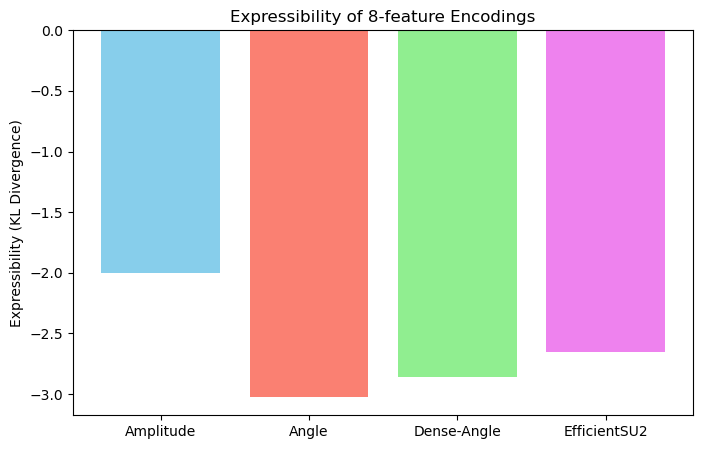

In [41]:
# --- Example usage with your dataset ---
from tqdm import tqdm  # progress bar
X = first_n_scaled_testing_data

encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

expressibilities = {}
for name, fn in tqdm(encoding_fns.items(), desc="Computing expressibility", unit="encoding"):
    expressibilities[name] = compute_expressibility_dataset(fn, X)
    tqdm.write(f"{name} expressibility ≈ {expressibilities[name]:.3f}")

# === Plot ===
plt.figure(figsize=(8,5))
plt.bar(expressibilities.keys(), expressibilities.values(),
        color=['skyblue','salmon','lightgreen','violet'])
plt.ylabel("Expressibility (KL Divergence)")
plt.title("Expressibility of 8-feature Encodings")
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from qiskit.quantum_info import Statevector
from tqdm import tqdm

def visualize_tsne_for_encoding(encoding_fn, X, y, num_samples=200, seed=42):
    """
    Visualize quantum encoded states in 2D using t-SNE.
    Works with pandas or NumPy inputs.
    """
    # Ensure numpy arrays
    X = np.array(X)
    y = np.array(y)
    
    # Sample indices
    num_samples = min(num_samples, len(X))
    idxs = np.random.choice(len(X), size=num_samples, replace=False)
    
    # Encode states
    states = []
    for i in tqdm(idxs, desc="Encoding states"):
        qc = encoding_fn(X[i])
        sv = Statevector.from_instruction(qc)
        states.append(sv.data)
    
    states = np.array(states)  # shape: (num_samples, dim)
    
    # Flatten real+imag for t-SNE
    features_real = np.hstack([states.real, states.imag])
    
    # t-SNE
    tsne = TSNE(n_components=2, random_state=seed, perplexity=30)
    coords = tsne.fit_transform(features_real)  # shape: (num_samples, 2)
    
    # Plot
    plt.figure(figsize=(7,5))
    normal_mask = (y[idxs] == 0)
    anomalous_mask = (y[idxs] == 1)
    
    if np.sum(normal_mask) > 0:
        plt.scatter(coords[normal_mask, 0], coords[normal_mask, 1], 
                    alpha=0.6, c='blue', label='Normal')
    if np.sum(anomalous_mask) > 0:
        plt.scatter(coords[anomalous_mask, 0], coords[anomalous_mask, 1], 
                    alpha=0.6, c='red', label='Anomalous')
    
    plt.title(f"t-SNE of Encoded States — {encoding_fn.__name__}")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.show()


In [17]:
X = first_n_scaled_testing_data   # already a NumPy array
y = testing_labels        # already a NumPy array (or convert with np.array(testing_labels) if it’s a list/Series)


encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

# for name, fn in encoding_fns.items():
#     print(f"\n--- {name} Encoding ---")
#     visualize_tsne_for_encoding(fn, X, y, num_samples=300)


--- Amplitude Encoding ---


Encoding states: 100%|█████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 2144.99it/s]


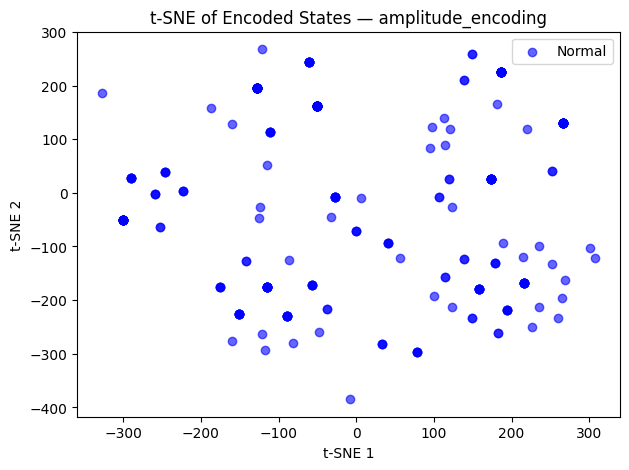


--- Angle Encoding ---


Encoding states: 100%|█████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 1981.29it/s]


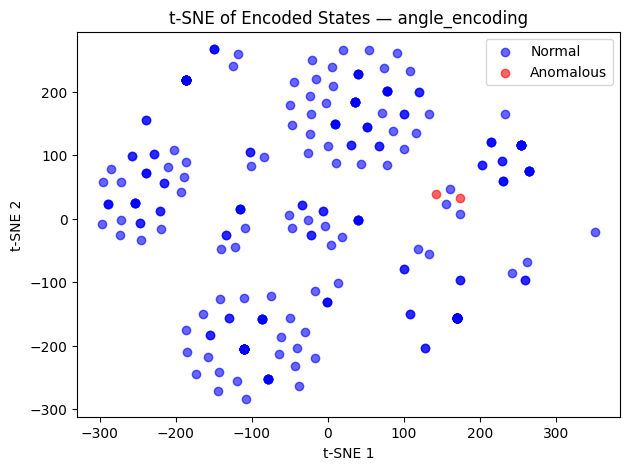


--- Dense-Angle Encoding ---


Encoding states: 100%|█████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 1991.10it/s]


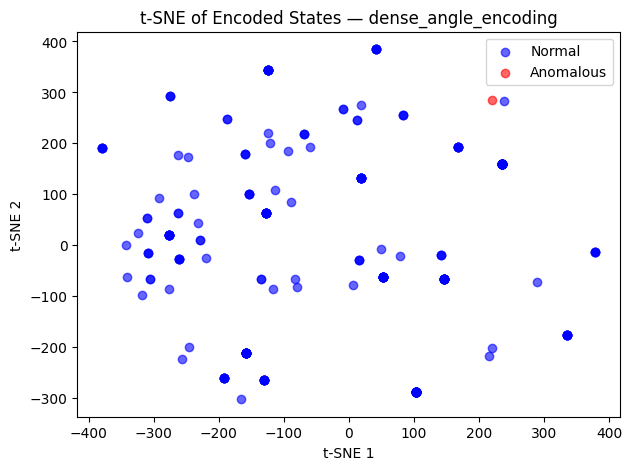


--- EfficientSU2 Encoding ---


Encoding states: 100%|██████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 342.68it/s]


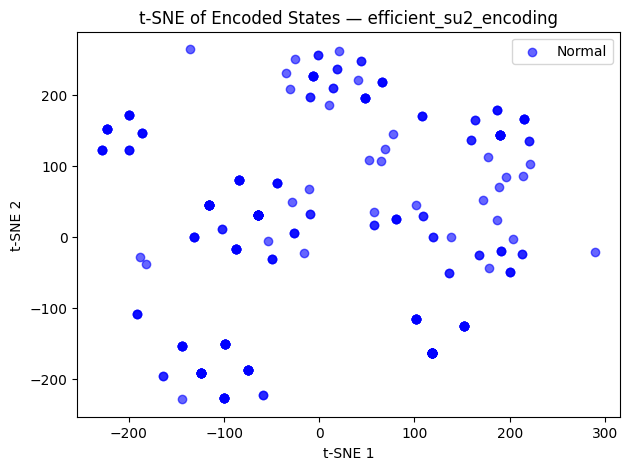

In [10]:
X = first_n_scaled_normal_training_data   # already a NumPy array
y = training_labels        # already a NumPy array (or convert with np.array(testing_labels) if it’s a list/Series)


encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

for name, fn in encoding_fns.items():
    print(f"\n--- {name} Encoding ---")
    visualize_tsne_for_encoding(fn, X, y, num_samples=300)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

def tsne_plot_raw(X, y, title="t-SNE of Raw Data", num_samples=300, seed=42):
    """
    t-SNE visualization of raw data.
    X: ndarray (N_samples, N_features)
    y: labels (0 normal, 1 anomalous)
    """
    X = np.array(X)
    y = np.array(y)
    
    # Sample a subset for faster computation
    num_samples = min(num_samples, len(X))
    idxs = np.random.choice(len(X), size=num_samples, replace=False)
    X_sample = X[idxs]
    y_sample = y[idxs]
    
    tsne = TSNE(n_components=2, random_state=seed, perplexity=30)
    coords = tsne.fit_transform(X_sample)
    
    plt.figure(figsize=(7,5))
    plt.scatter(coords[y_sample==0, 0], coords[y_sample==0, 1], 
                c='blue', alpha=0.6, label='Normal')
    plt.scatter(coords[y_sample==1, 0], coords[y_sample==1, 1], 
                c='red', alpha=0.6, label='Anomalous')
    plt.title(title)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.show()

def feature_variances(X):
    """Compute variance per feature."""
    X = np.array(X)
    return np.var(X, axis=0)

def tsne_and_variance_random_features(X, y, N, seed=42, num_samples=300, show_tsne=True):
    """
    Select N random features, run t-SNE (optional), and show variance statistics.
    
    X: ndarray (num_samples, num_features)
    y: labels (0 normal, 1 anomalous)
    N: number of features to randomly select
    show_tsne: whether to plot t-SNE visualization
    """
    np.random.seed(seed)
    feature_indices = np.random.choice(X.shape[1], size=N, replace=False)
    print(f"\nRandom feature indices: {feature_indices}")
    
    X_random = X[:, feature_indices]

    # Optionally show t-SNE
    if show_tsne:
        tsne_plot_raw(X_random, y, title=f"t-SNE: Random {N} Features", num_samples=num_samples)
    
    # Variance scores
    var_random = feature_variances(X_random)
    mean_var = np.mean(var_random)
    std_var = np.std(var_random)
    min_var = np.min(var_random)
    max_var = np.max(var_random)
    
    print("Variance statistics:")
    print(f"  Mean variance: {mean_var:.6f}")
    print(f"  Std of variances: {std_var:.6f}")
    print(f"  Min variance: {min_var:.6f}")
    print(f"  Max variance: {max_var:.6f}")
    print(f"  All variances: {np.round(var_random, 6)}\n")
    
    return feature_indices, var_random


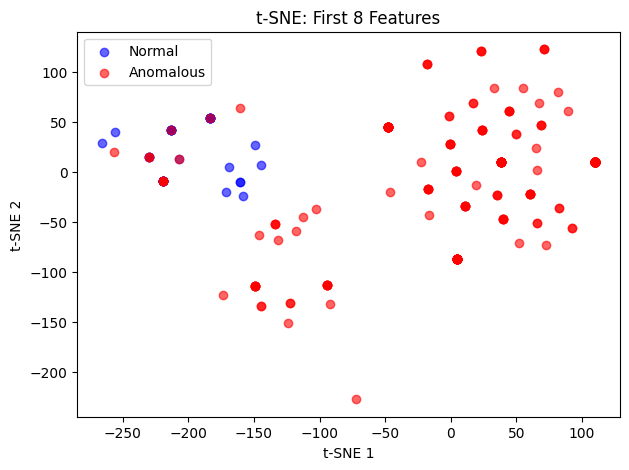


First 8 Features Variance Stats:
  Mean variance: 0.436601
  Std of variances: 0.518272
  Min variance: 0.017258
  Max variance: 1.371513
  All variances: [0.10693  0.464369 1.235267 0.017258 0.160733 1.371513 0.021875 0.114867]


In [36]:
N = 8
feature_indices = np.arange(N)       # first N features
X_firstN = scaled_testing_data[:, feature_indices]

# t-SNE
tsne_plot_raw(X_firstN, y, title=f"t-SNE: First {N} Features", num_samples=300)

# Variance
var_firstN = feature_variances(X_firstN)
print(f"\nFirst {N} Features Variance Stats:")
print(f"  Mean variance: {np.mean(var_firstN):.6f}")
print(f"  Std of variances: {np.std(var_firstN):.6f}")
print(f"  Min variance: {np.min(var_firstN):.6f}")
print(f"  Max variance: {np.max(var_firstN):.6f}")
print(f"  All variances: {np.round(var_firstN, 6)}")


Random feature indices: [18 23  7 14 10 13  8 21]


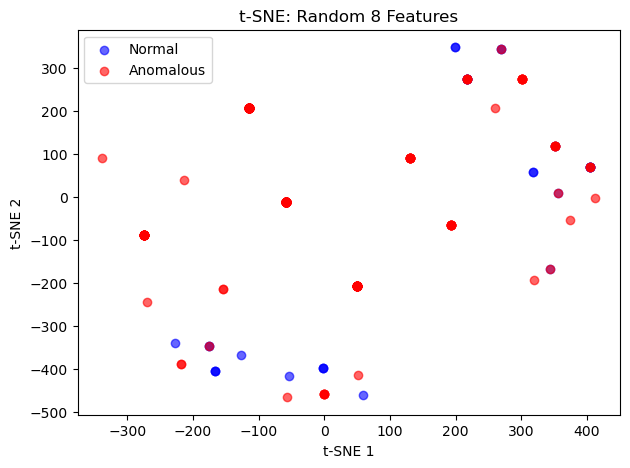

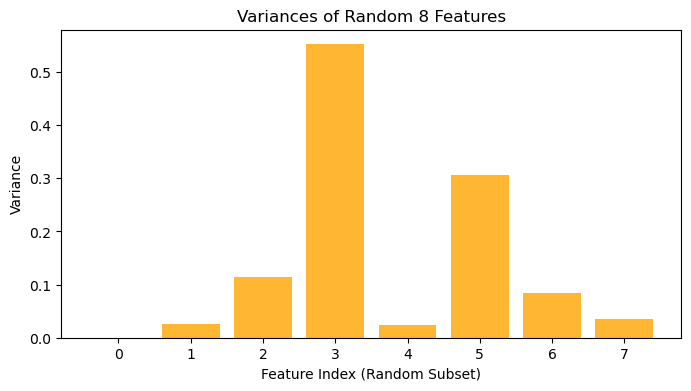

In [76]:
N = 8
random_indices, random_vars = tsne_and_variance_random_features(scaled_testing_data, y, N, seed=12)

<>:16: SyntaxWarning: invalid escape sequence '\C'
<>:16: SyntaxWarning: invalid escape sequence '\C'
C:\Users\Rohan\AppData\Local\Temp\ipykernel_26620\708802190.py:16: SyntaxWarning: invalid escape sequence '\C'
  print(f"\Custom Features Variance Stats:")


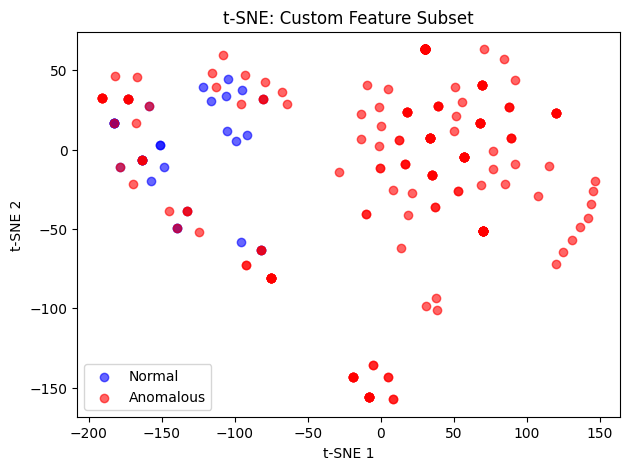

\Custom Features Variance Stats:
  Mean variance: 0.273960
  Std of variances: 0.438252
  Min variance: 0.000136
  Max variance: 1.371513
  All variances: [1.607330e-01 1.371513e+00 1.725800e-02 4.643690e-01 1.069300e-01
 4.518400e-02 2.555300e-02 1.360000e-04]


In [41]:
# Define the specific features you want
# feature_indices = [20, 10, 15, 0, 1, 11, 13, 9]
#feature_indices = [6, 0, 21, 17, 11, 16, 4, 5]
#feature_indices = [22, 2, 17, 16, 19, 21, 18, 1]
#feature_indices = [2, 21, 22, 1, 17, 16, 19, 18]
feature_indices = [4, 5, 3, 1, 0, 16, 23, 18]

# Slice your dataset
X_selected = scaled_testing_data[:, feature_indices]

# t-SNE
tsne_plot_raw(X_selected, y, title=f"t-SNE: Custom Feature Subset")

# Feature variances
var = feature_variances(X_selected)
print(f"\Custom Features Variance Stats:")
print(f"  Mean variance: {np.mean(var):.6f}")
print(f"  Std of variances: {np.std(var):.6f}")
print(f"  Min variance: {np.min(var):.6f}")
print(f"  Max variance: {np.max(var):.6f}")
print(f"  All variances: {np.round(var, 6)}")

# print("Scaled data shape:", scaled_testing_data.shape)
# print("First 5 rows:\n", scaled_testing_data[:5])


<>:25: SyntaxWarning: invalid escape sequence '\C'
<>:25: SyntaxWarning: invalid escape sequence '\C'
C:\Users\Rohan\AppData\Local\Temp\ipykernel_26620\3835829445.py:25: SyntaxWarning: invalid escape sequence '\C'
  print(f"\Custom Features Variance Stats:")


Balanced feature indices: [23 13  1 14  2  5]


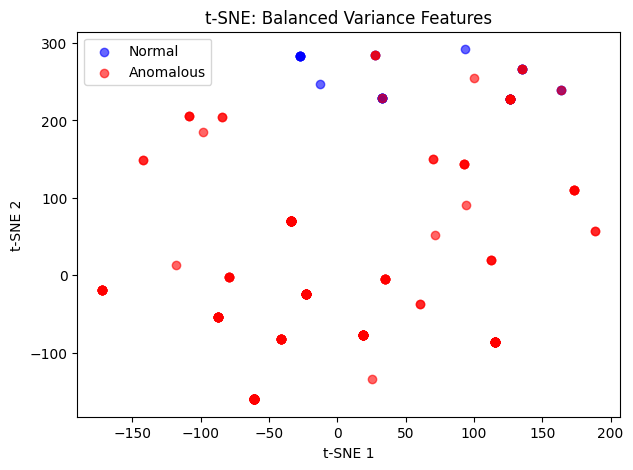

\Custom Features Variance Stats:
  Mean variance: 0.658990
  Std of variances: 0.485703
  Min variance: 0.025553
  Max variance: 1.371513
  All variances: [0.025553 0.305335 0.464369 0.551902 1.235267 1.371513]


In [50]:
import numpy as np

X = np.array(scaled_testing_data)  # your dataset
var = np.var(X, axis=0)            # variance per feature
sorted_indices = np.argsort(var)  # low → high
N_total = 8

# Compute number from each category
N_each_low  = 0      
N_each_mid  = 1      
N_each_high = 5

# Pick indices
low_idx  = sorted_indices[:N_each_low]
mid_idx  = sorted_indices[len(sorted_indices)//3 : len(sorted_indices)//3 + N_each_mid]
high_idx = sorted_indices[-N_each_high:]

balanced_indices = np.concatenate([low_idx, mid_idx, high_idx])
print("Balanced feature indices:", balanced_indices)
X_balanced = X[:, balanced_indices]

tsne_plot_raw(X_balanced, y, title="t-SNE: Balanced Variance Features")

var_selected = feature_variances(X_balanced)
print(f"\Custom Features Variance Stats:")
print(f"  Mean variance: {np.mean(var_selected):.6f}")
print(f"  Std of variances: {np.std(var_selected):.6f}")
print(f"  Min variance: {np.min(var_selected):.6f}")
print(f"  Max variance: {np.max(var_selected):.6f}")
print(f"  All variances: {np.round(var_selected, 6)}")


In [8]:
# =============================
# Intuition Builder – 5 Experiments
# =============================
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score

from qiskit.quantum_info import Statevector, DensityMatrix

# -----------------------------
# Config
# -----------------------------
X = np.array(first_n_scaled_testing_data)      # shape: (n_samples, n_features)
y = np.array(testing_labels).astype(int)       # 0 normal, 1 anomalous
assert X.ndim == 2, "X must be 2D"
assert y.ndim == 1 and len(y) == len(X), "y must align with X"

encoding_fns = {
    "Amplitude": amplitude_encoding,
    "Angle": angle_encoding,
    "Dense-Angle": dense_angle_encoding,
    "EfficientSU2": efficient_su2_encoding
}

RNG = np.random.default_rng(42)
TSNE_MAX_SAMPLES = 600       # cap for speed; adjust if needed
EXP_NUM_SAMPLES = 200        # samples to estimate expressibility & histograms

# -----------------------------
# Utilities
# -----------------------------
def _safe_sample_indices(n_total, n_wanted):
    return RNG.choice(n_total, size=min(n_total, n_wanted), replace=False)

def encode_dataset_statevectors(encoding_fn, X, num_samples=200, desc="Encoding"):
    idxs = _safe_sample_indices(len(X), num_samples)
    states = []
    for i in tqdm(idxs, desc=desc, leave=False):
        qc = encoding_fn(X[i])
        sv = Statevector.from_instruction(qc)
        states.append(sv.data)     # complex vector
    return np.array(states), idxs

def tsne_2d(arr, seed=42):
    # arr shape: (n_samples, n_features)
    n = len(arr)
    if n < 5:
        raise ValueError("Need at least 5 samples for stable t-SNE")
    perplexity = max(5, min(30, n // 3))
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=seed, init="pca")
    return tsne.fit_transform(arr)

def plot_two_class_scatter(coords, labels, title):
    plt.figure(figsize=(7,5))
    m0 = labels == 0
    m1 = labels == 1
    if np.any(m0):
        plt.scatter(coords[m0,0], coords[m0,1], alpha=0.65, label="Normal", s=24)
    if np.any(m1):
        plt.scatter(coords[m1,0], coords[m1,1], alpha=0.65, label="Anomalous", s=24)
    plt.title(title)
    plt.xlabel("Dim 1")
    plt.ylabel("Dim 2")
    plt.legend()
    plt.tight_layout()
    plt.show()

def compute_pairwise_fidelities(states_a, states_b=None):
    """
    If states_b is None → within-set pairwise (i<j).
    If states_b provided → across-set pairwise (all pairs).
    Returns list of |<psi|phi>|^2 values.
    """
    if states_b is None:
        fid = []
        for i in range(len(states_a)):
            ai = states_a[i]
            for j in range(i+1, len(states_a)):
                bj = states_a[j]
                f = np.abs(np.vdot(ai, bj))**2
                fid.append(f)
        return np.array(fid, dtype=float)
    else:
        fid = []
        for i in range(len(states_a)):
            ai = states_a[i]
            for j in range(len(states_b)):
                bj = states_b[j]
                f = np.abs(np.vdot(ai, bj))**2
                fid.append(f)
        return np.array(fid, dtype=float)

# -----------------------------
# Experiment 1:
# Variance & Raw t-SNE (no encoding)
# -----------------------------
def exp1_variance_and_raw_tsne(X, y, title_suffix="(First-N Features)"):
    # Variances
    var = np.var(X, axis=0)
    plt.figure(figsize=(8,3.6))
    plt.bar(np.arange(len(var)), var, alpha=0.8)
    plt.xlabel("Feature Index")
    plt.ylabel("Variance")
    plt.title(f"Feature Variances {title_suffix}")
    plt.tight_layout()
    plt.show()

    # Raw t-SNE
    idxs = _safe_sample_indices(len(X), TSNE_MAX_SAMPLES)
    Xs, ys = X[idxs], y[idxs]
    coords = tsne_2d(Xs)
    plot_two_class_scatter(coords, ys, f"t-SNE of Raw Features {title_suffix}")

# -----------------------------
# Experiment 2:
# Expressibility (Sim et al. proxied via KL on fidelity hist vs U[0,1])
# + optional correlation with performance (provide dict if you have it)
# -----------------------------
from scipy.stats import entropy as KLdiv

def compute_expressibility_dataset(encoding_fn, X, num_samples=200, bins=50):
    states, _ = encode_dataset_statevectors(encoding_fn, X, num_samples, desc="Encoding for expressibility")
    # random pairs fidelity distribution
    fids = compute_pairwise_fidelities(states)
    if len(fids) == 0:
        return np.nan
    # Haar proxy: U[0,1] for fidelity distribution baseline in large-dim limit
    # (good heuristic; exact Haar depends on dimension)
    haar = RNG.random(len(fids))
    he, _ = np.histogram(fids, bins=bins, range=(0,1), density=True)
    hh, _ = np.histogram(haar, bins=bins, range=(0,1), density=True)
    he += 1e-12; hh += 1e-12
    # Lower KL → closer to Haar → "more expressive". We plot 1/KL for readability.
    kl = KLdiv(he, hh)
    score = 1.0 / kl if kl > 0 else np.inf
    return score

def exp2_expressibility_vs_performance(X, encoding_fns, perf_by_encoding=None):
    scores = {}
    for name, fn in encoding_fns.items():
        scores[name] = compute_expressibility_dataset(fn, X, num_samples=EXP_NUM_SAMPLES)
        print(f"Expressibility (1/KL) - {name}: {scores[name]:.4f}")

    # Bar plot of expressibility
    plt.figure(figsize=(7,4))
    plt.bar(list(scores.keys()), list(scores.values()), alpha=0.85)
    plt.ylabel("Expressibility (higher ≈ closer to Haar)")
    plt.title("Expressibility by Encoding")
    plt.tight_layout()
    plt.show()

    # Optional: correlate with your test AUC (or any metric)
    if perf_by_encoding is not None:
        # Align keys
        common = [k for k in scores if k in perf_by_encoding]
        xs = np.array([scores[k] for k in common], dtype=float)
        ys = np.array([perf_by_encoding[k] for k in common], dtype=float)

        # Scatter correlation
        plt.figure(figsize=(5.2,4.4))
        plt.scatter(xs, ys, s=60)
        for k, x, yv in zip(common, xs, ys):
            plt.annotate(k, (x, yv), textcoords="offset points", xytext=(5,5))
        plt.xlabel("Expressibility (1/KL)")
        plt.ylabel("Model Performance (e.g., AUC)")
        plt.title("Performance vs Expressibility")
        plt.tight_layout()
        plt.show()

# -----------------------------
# Experiment 3:
# Fidelity Separation (NN, AA, NA histograms)
# -----------------------------
def exp3_fidelity_histograms(X, y, encoding_fns, num_samples=200, bins=40):
    idxs = _safe_sample_indices(len(X), num_samples)
    Xs, ys = X[idxs], y[idxs]
    for name, fn in encoding_fns.items():
        print(f"\nFidelity histograms — {name}")
        states, _ = encode_dataset_statevectors(fn, Xs, num_samples=len(Xs), desc=f"Encoding ({name})")
        m0 = ys == 0
        m1 = ys == 1
        s0 = states[m0]
        s1 = states[m1]
        if len(s0) < 2 or len(s1) < 1:
            print("Not enough samples in one of the classes to build histograms.")
            continue
        f_nn = compute_pairwise_fidelities(s0)
        f_aa = compute_pairwise_fidelities(s1) if len(s1) >= 2 else np.array([])
        f_na = compute_pairwise_fidelities(s0, s1)

        plt.figure(figsize=(8,4.2))
        if len(f_nn): plt.hist(f_nn, bins=bins, alpha=0.55, label="Normal–Normal")
        if len(f_aa): plt.hist(f_aa, bins=bins, alpha=0.55, label="Anom–Anom")
        if len(f_na): plt.hist(f_na, bins=bins, alpha=0.55, label="Normal–Anom")
        plt.xlabel("Fidelity |⟨ψ|φ⟩|²")
        plt.ylabel("Count")
        plt.title(f"Pairwise Fidelity Distributions — {name}")
        plt.legend()
        plt.tight_layout()
        plt.show()

# -----------------------------
# Experiment 4:
# Latent Space Visualization (QAE outputs)
# You provide latent z per encoding; we visualize it.
# -----------------------------
def plot_latent_tsne(z, y, title="Latent t-SNE"):
    z = np.array(z)
    y = np.array(y)
    idxs = _safe_sample_indices(len(z), TSNE_MAX_SAMPLES)
    coords = tsne_2d(z[idxs])
    plot_two_class_scatter(coords, y[idxs], title)

def exp5_latent_visualization(latent_by_encoding, y, title_prefix="QAE Latent"):
    """
    latent_by_encoding: dict {encoding_name: z_array}
        where z_array has shape (n_samples, latent_dim) and aligns with y.
    """
    for name, z in latent_by_encoding.items():
        plot_latent_tsne(z, y, title=f"{title_prefix} — {name}")


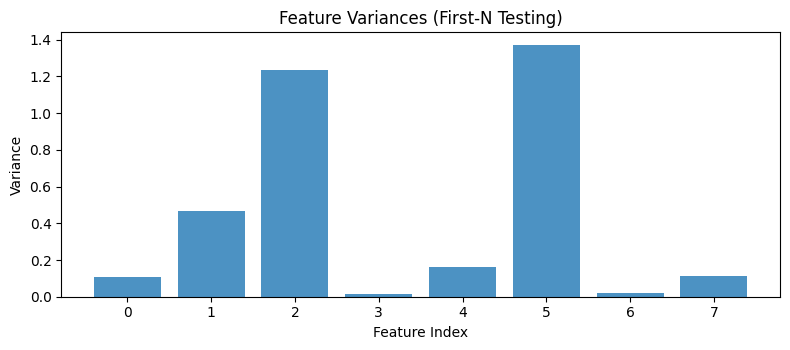

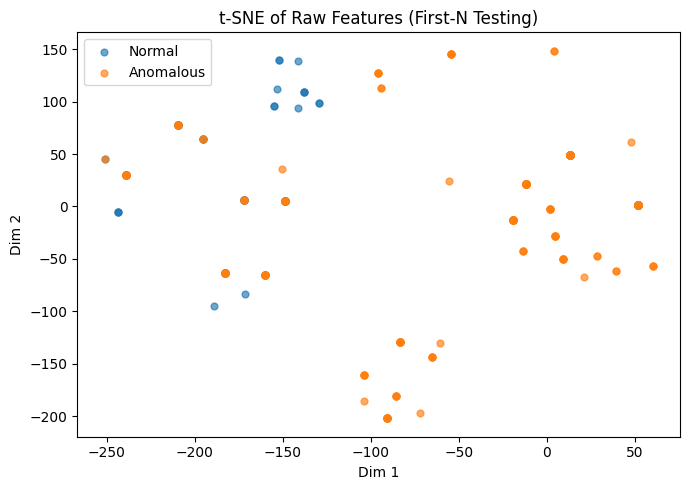

Expressibility (1/KL) - Amplitude: 0.3901


Expressibility (1/KL) - Angle: 0.3418


Expressibility (1/KL) - Dense-Angle: 0.3546


Expressibility (1/KL) - EfficientSU2: 0.3976


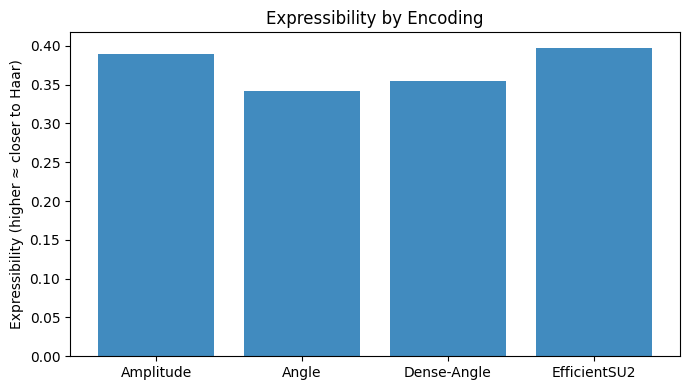


Fidelity histograms — Amplitude


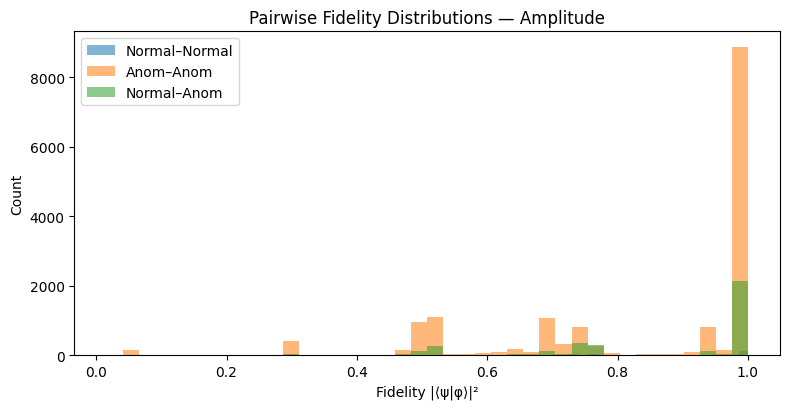


Fidelity histograms — Angle


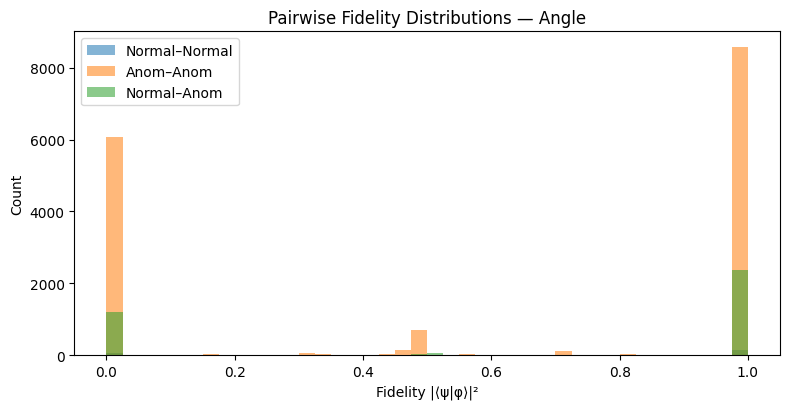


Fidelity histograms — Dense-Angle


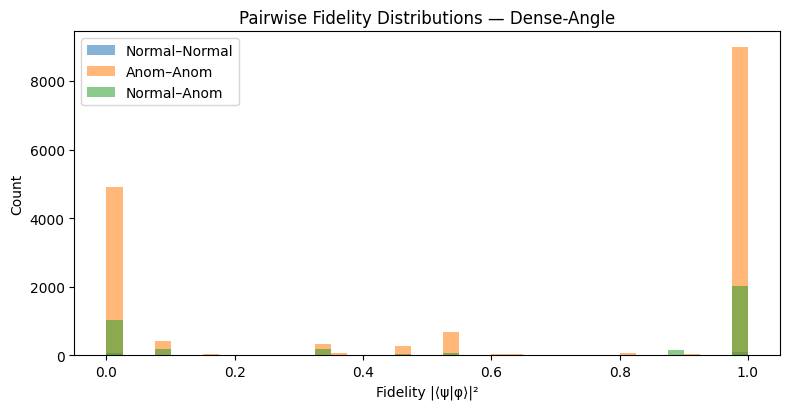


Fidelity histograms — EfficientSU2


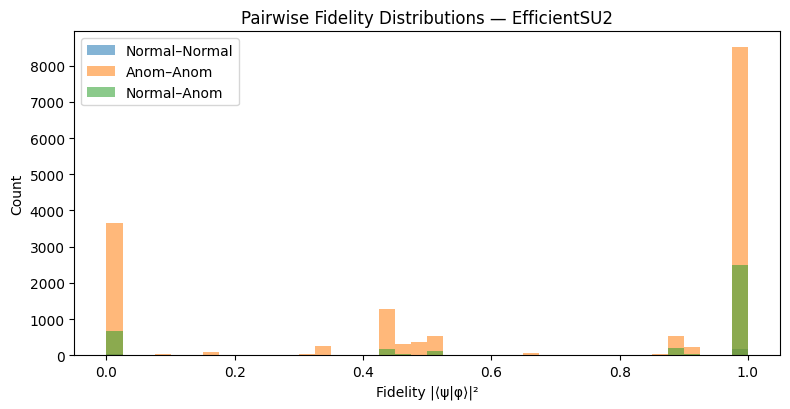

In [9]:
# =============================
# Run the experiments
# =============================

# 1) Variance & raw t-SNE
exp1_variance_and_raw_tsne(X, y, title_suffix="(First-N Testing)")

# 2) Expressibility (+ optional correlation if you have perf metrics)
# Example: perf_by_encoding = {"Amplitude": 0.81, "Angle": 0.78, "Dense-Angle": 0.83, "EfficientSU2": 0.79}
perf_by_encoding = None
exp2_expressibility_vs_performance(X, encoding_fns, perf_by_encoding=perf_by_encoding)

# 3) Fidelity separation histograms
exp3_fidelity_histograms(X, y, encoding_fns, num_samples=EXP_NUM_SAMPLES, bins=40)

# 4) Latent visualization (provide your QAE latents)
# Example usage once you have them:
# latent_by_encoding = {
#     "Amplitude": z_amp,     # shape (n_samples, latent_dim)
#     "Angle": z_ang,
#     "Dense-Angle": z_dang,
#     "EfficientSU2": z_su2
# }
# exp5_latent_visualization(latent_by_encoding, y, title_prefix="QAE Latent")

In [32]:
import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector

# --- helper to get vectorized representation after encoding ---
def encode_to_vector(data, encoding_fn, max_samples=200):
    """
    Encode classical data into quantum states and extract vectors for t-SNE.
    """
    vectors = []
    backend = Aer.get_backend("statevector_simulator")

    for x in data[:max_samples]:
        qc = encoding_fn(x)

        # Run statevector simulator
        t_qc = transpile(qc, backend)
        result = backend.run(t_qc).result()
        state = Statevector(result.get_statevector(t_qc))

        # Flatten amplitudes (real+imag parts)
        vec = np.concatenate([state.data.real, state.data.imag])
        vectors.append(vec)

    return np.array(vectors)

# --- t-SNE plot
def tsne_plot_encoded(
    raw_data, 
    scaled_data, 
    labels, 
    encoding_fns, 
    names, 
    max_samples=300
):
    """
    Compare raw t-SNE with encoded t-SNEs for different encodings.
    Uses scaled data for amplitude encoding, raw for others.
    """
    fig, axes = plt.subplots(1, len(encoding_fns) + 1, figsize=(5 * (len(encoding_fns) + 1), 4))

    # Subsample for consistency
    max_samples = min(max_samples, len(raw_data))
    raw_subset = raw_data[:max_samples]
    scaled_subset = scaled_data[:max_samples]
    labels_subset = labels[:max_samples]

    # 1. Raw data t-SNE
    raw_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(raw_subset)
    axes[0].scatter(raw_tsne[labels_subset==0, 0], raw_tsne[labels_subset==0, 1],
                    c="blue", alpha=0.6, label="Normal")
    axes[0].scatter(raw_tsne[labels_subset==1, 0], raw_tsne[labels_subset==1, 1],
                    c="red", alpha=0.6, label="Anomalous")
    axes[0].set_title("Raw Data")
    axes[0].legend()

    # 2. Encoded versions
    for i, (fn, name) in enumerate(zip(encoding_fns, names)):
        if name != "Amplitude":
            data = scaled_subset   # amplitude needs scaled
        else:
            data = raw_subset      # others use raw

        encoded_vectors = encode_to_vector(data, fn, max_samples=max_samples)
        encoded_tsne = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(encoded_vectors)

        axes[i+1].scatter(encoded_tsne[labels_subset==0, 0], encoded_tsne[labels_subset==0, 1],
                          c="blue", alpha=0.6, label="Normal")
        axes[i+1].scatter(encoded_tsne[labels_subset==1, 0], encoded_tsne[labels_subset==1, 1],
                          c="red", alpha=0.6, label="Anomalous")
        axes[i+1].set_title(f"{name} Encoding")
        axes[i+1].legend()

    plt.tight_layout()
    plt.show()

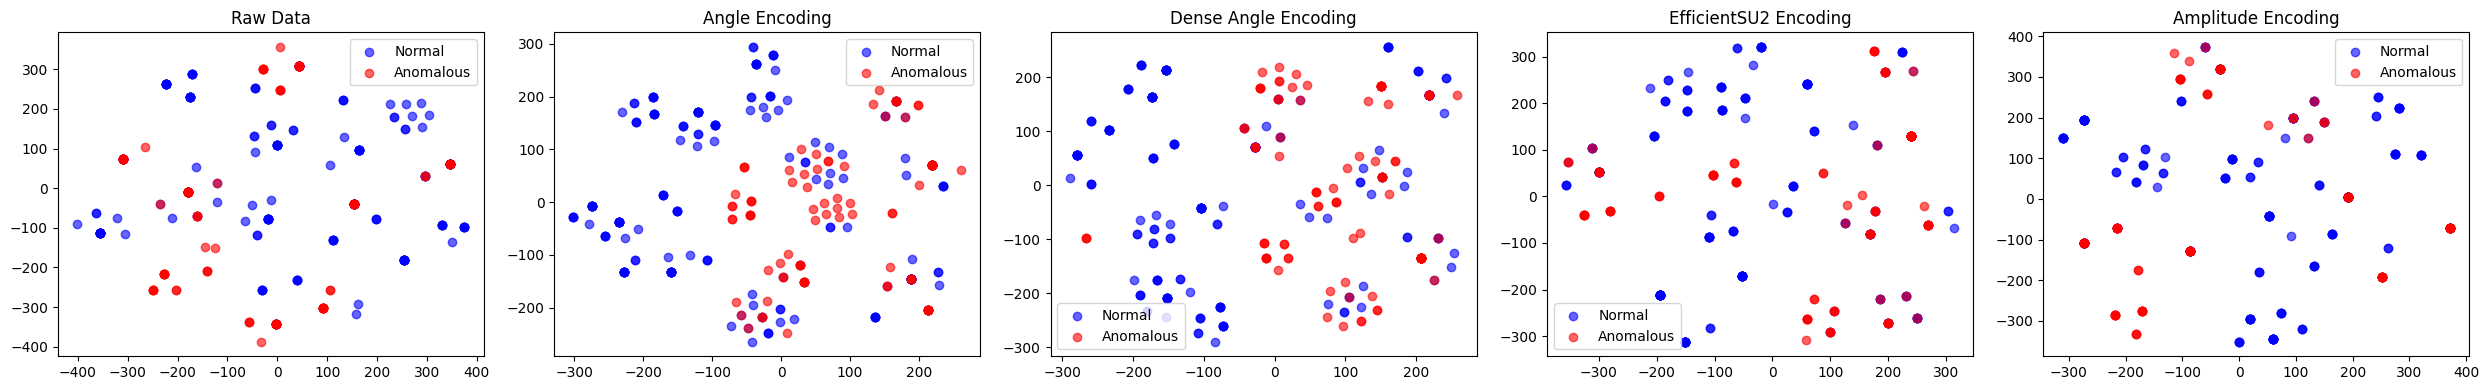

In [34]:
encoding_fns = [angle_encoding, dense_angle_encoding, efficient_su2_encoding, amplitude_encoding]
encoding_names = ["Angle", "Dense Angle", "EfficientSU2", "Amplitude"]

tsne_plot_encoded(
    raw_data=first_n_testing_data,  
    scaled_data=first_n_scaled_testing_data,    
    labels=y,
    encoding_fns=encoding_fns,
    names=encoding_names,
    max_samples=300
)


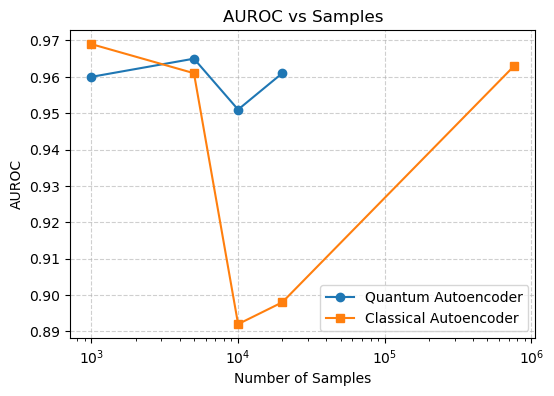

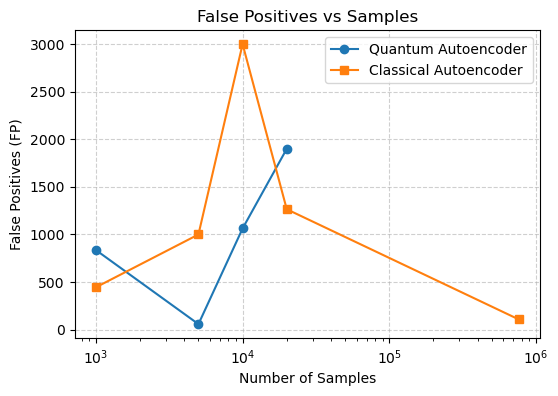

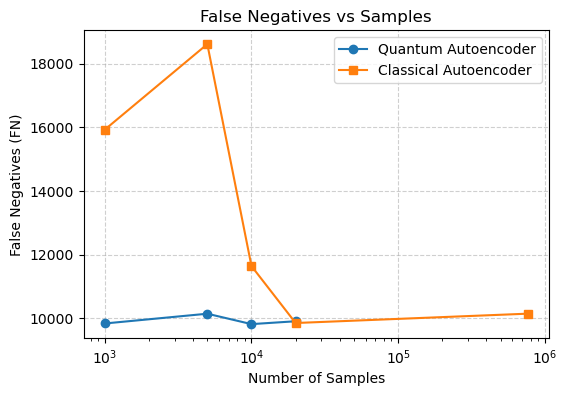

In [5]:
import matplotlib.pyplot as plt

# --- Quantum data ---
q_samples = [1000, 5000, 10000, 20000]
q_auroc = [0.960, 0.965, 0.951, 0.961]
q_fp = [835, 57, 1062, 1899]
q_fn = [9839, 10146, 9819, 9909]

# --- Classical data (including Full dataset) ---
c_samples = [1000, 5000, 10000, 20000, 761875]  # Full dataset
c_auroc = [0.969, 0.961, 0.892, 0.898, 0.963]
c_fp = [444, 999, 2999, 1264, 107]
c_fn = [15928, 18615, 11642, 9854, 10147]

# --- Plot AUROC ---
plt.figure(figsize=(6,4))
plt.plot(q_samples, q_auroc, marker='o', label="Quantum Autoencoder")
plt.plot(c_samples, c_auroc, marker='s', label="Classical Autoencoder")
plt.xlabel("Number of Samples")
plt.ylabel("AUROC")
plt.title("AUROC vs Samples")
plt.xscale('log')  # log scale helps with huge Full dataset
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# --- Plot False Positives ---
plt.figure(figsize=(6,4))
plt.plot(q_samples, q_fp, marker='o', label="Quantum Autoencoder")
plt.plot(c_samples, c_fp, marker='s', label="Classical Autoencoder")
plt.xlabel("Number of Samples")
plt.ylabel("False Positives (FP)")
plt.title("False Positives vs Samples")
plt.xscale('log')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# --- Plot False Negatives ---
plt.figure(figsize=(6,4))
plt.plot(q_samples, q_fn, marker='o', label="Quantum Autoencoder")
plt.plot(c_samples, c_fn, marker='s', label="Classical Autoencoder")
plt.xlabel("Number of Samples")
plt.ylabel("False Negatives (FN)")
plt.title("False Negatives vs Samples")
plt.xscale('log')
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
